# Fine-tune MedImageParse3D on BHSD

Train a five-class intracranial hemorrhage segmentation model with this workflow:

**Training and evaluation**

1. Prepare BHSD training slices and test volumes.
2. Fine-tune the base model.
3. Score the test volumes with the fine-tuned model.
4. Evaluate segmentation metrics against the reference masks.

Evaluation runs inside the Azure Machine Learning pipeline; no endpoint is needed.

**Deployment and inference**

1. Register the exported model.
2. Deploy it to a managed online endpoint.
3. Invoke the endpoint on a test volume and visualize the prediction.

## 1. Set up the notebook

**Prerequisites**

- Python 3.10 or 3.11; the setup below uses 3.11.
- An Azure Machine Learning workspace and an existing GPU compute cluster.
- A cluster managed identity with access to the workspace datastore and model registries.
- One GPU for this BF16 mixed-precision recipe, previously exercised on A100 and H100 compute.

**Before running**

1. Open the notebook from its own directory so helper imports and relative paths resolve.
2. Authenticate with `az login` and select your subscription.
3. Install the local dependencies below, then fill in the workspace, compute, and data settings.

Set `completed_job_name` to `None` for a new training run, or to a completed parent pipeline name to reuse its results and model. Run the cells in order: a completed job skips data preparation and training automatically. Set `prepared_dir` to that job's prepared data for sample inference. Section 6 reuses the named deployment or registers and deploys the model if it is missing; cleanup remains a separate optional step.

Training and scoring use registered Azure ML environments, not this local Python environment.

**Local Python requirements**

Use a fresh Python 3.11 environment and install the [repository package](../../../package/pyproject.toml) with its `examples` extra. Run these commands in your terminal from the repository root; the notebook does not install packages:

```bash
uv venv --python 3.11
source .venv/bin/activate
uv pip install -e './package[examples]'
az login
cd azureml/medimageparse3d/finetuning
```

Select that environment as the notebook kernel. The package provides the local dependencies, including OpenCV, plotting, and notebook support. Do not also install `opencv-python-headless`: the package uses `opencv-python`, and both provide the same `cv2` module.

In [ ]:
import json
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display
from azure.ai.ml import MLClient, Input, dsl
from azure.ai.ml.constants import AssetTypes
from azure.ai.ml.entities import UserIdentityConfiguration
from azure.identity import DefaultAzureCredential

from scripts.prepare_data import prepare_slices, prepare_volumes
from components.components import get_score_component, get_evaluate_component
from scripts.get_metrics import download_metrics

In [ ]:
# Azure ML workspace and training
subscription_id = "<subscription-id>"
resource_group = "<resource-group>"
workspace_name = "<workspace-name>"
compute_name = "<gpu-compute-name>"
experiment_name = "mip3d-bhsd-finetuning"

# Dataset paths
dataset_root = "/path/to/BHSD"
prepared_dir = "prepared/bhsd"
evaluation_dir = f"{prepared_dir}/evaluation"

# Set a completed parent job name to use it and skip training
# or set to None to train a new model.
completed_job_name = None

# Model registration and deployment
model_name = "mip3d-bhsd"
endpoint_name = "<unique-endpoint-name>"
deployment_name = "ich"
instance_type = "Standard_NC40ads_H100_v5"

# Data preparation recipe (used only for a new training run)
window_width = 200
window_level = 40
target_repeat = {1: 5, 5: 5}
negative_sample_ratio = 0.15
seed = 0

dataset_root = Path(dataset_root)
prepared_dir = Path(prepared_dir)
evaluation_dir = Path(evaluation_dir)
training_dir = prepared_dir / "training"

credential = DefaultAzureCredential(exclude_managed_identity_credential=True)
ml_client = MLClient(credential, subscription_id, resource_group, workspace_name)
print("workspace name", ml_client.workspaces.get(workspace_name).name)

Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented


workspace name <workspace-name>


## 2. Resolve the base model and its environment

- Resolve the base model's `latest` label once, then pass its concrete ID to training.
- Use the model's `inference_environment_asset_id` tag for scoring and serving.

The pipeline records the environment tag on the job. Deployment reads it from that job instead of resolving a potentially different catalog environment later.

In [22]:
model_registry_client = MLClient(credential, registry_name="azureml-ai-frontiers")
base_model = model_registry_client.models.get(name="MedImageParse3d", label="latest")
inference_environment = base_model.tags["inference_environment_asset_id"]

component_registry_client = MLClient(credential, registry_name="azureml")
finetune = component_registry_client.components.get(
    name="medimageparse_3d_finetune", version="0.0.2"
)
score = get_score_component(inference_environment)
evaluate = get_evaluate_component(inference_environment)

print("Base model:", base_model.id)
print("Inference environment:", inference_environment)

Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented


Base model: azureml://registries/azureml-ai-frontiers/models/MedImageParse3d/versions/1
Inference environment: azureml://registries/azureml-ai-frontiers/environments/medimageparse3d_env_docker/versions/19


## 3. Prepare the training and test data

**Download and arrange BHSD**

1. Download [label_192.zip](https://huggingface.co/datasets/Wendy-Fly/BHSD/resolve/main/label_192.zip?download=true) and [dataset.json](https://huggingface.co/datasets/Wendy-Fly/BHSD/resolve/main/dataset.json?download=true) from [BHSD](https://huggingface.co/datasets/Wendy-Fly/BHSD).
2. Extract the archive into the layout below.
3. Set `dataset_root` in section 1 to the `BHSD` directory.

```text
BHSD/
├─ dataset.json
└─ label_192/
   ├─ images/
   │  └─ <case>.nii.gz
   └─ ground truths/
      └─ <case>.nii.gz
```

**Pairing and labels**

- Match each image to the label volume with the **same filename**.
- Use integer class maps: `0` is background; `1..5` are the targets below.
- Image and label must already share a voxel grid. Training checks array shapes, not physical alignment; reorientation is not registration.
- The notebook builds explicit `{case_id: {"image": path, "gt": path}}` mappings. Case IDs become output filename stems; image and mask filenames do not need to match for another dataset.
- Training reads NIfTI with NiBabel and MHA/NRRD with SimpleITK. Its loader returns canonical arrays in `(Z, H, W)` order with the requested dtype, without metadata. Scoring preparation reads NIfTI images and masks directly with NiBabel.

- **Training:** 92 of the 96 official volumes, after excluding four known affine mismatches.
- **Test:** all 96 official test volumes, kept separate for post-training evaluation.

Released class labels, including known annotation errors, are retained unchanged.

| Label | Class | Abbreviation |
|---|---|---|
| 1 | Epidural hemorrhage | EDH |
| 2 | Intraparenchymal hemorrhage | IPH |
| 3 | Intraventricular hemorrhage | IVH |
| 4 | Subarachnoid hemorrhage | SAH |
| 5 | Subdural hemorrhage | SDH |

The preparation cell below selects the volumes and exclusions, then calls `prepare_slices` for training and `prepare_volumes` for scoring and evaluation. See [scripts/prepare_data.py](scripts/prepare_data.py) for the transform assumptions.

### From volumes to training slices

Training consumes **2.5D images**: one target slice with neighboring slices as context. Scoring consumes **complete volumes**. Keep intensities, class IDs, and prompts consistent across both paths.

1. **Slice axis:** the loader reorients training pairs to canonical axes and returns `(Z, H, W)` arrays. Axis 0 (`Z`) is the axial slice dimension; images use `float32` and masks use `uint8`.
2. **Image size:** keep the existing 512x512 slices; no padding or resizing.
3. **Intensity:** use `window_width` and `window_level` from section 1. The default W200/L40 clips to [-60, 140] HU and scales to uint8 [0, 255]. Do not window masks or stretch contrast independently per slice.
4. **Channels:** pack `[current, previous, next]` as spatial context, not RGB colors. The mask labels only the current slice.

At a volume boundary, use the adjacent interior slice for the missing neighbor:

```text
Four-slice example:  [current, previous, next]
first slice          [0, 1, 1]
interior slice       [1, 0, 2]
last slice           [3, 2, 2]
```

> **Other image sizes:** match serving preprocessing when adapting the helper: center zero-pad to square, then resize to 512x512 with bicubic interpolation for images and nearest-neighbor for masks. Reorientation is not registration.

**Sampling is a recipe choice, separate from conversion.**

- Keep every slice containing a labeled hemorrhage.
- `negative_sample_ratio` in section 1 controls real no-hemorrhage slices per foreground slice in each training volume, before repetition. The default `0.15` samples about 15%, capped by available negatives; `0` omits them. These slices have empty masks.
- `target_repeat` in section 1 maps integer class IDs to **total** copies per slice. The default `{1: 5, 5: 5}` gives EDH/SDH-containing slices five records. If several classes match, use the largest count; unlisted classes and background slices get one copy. Use `{}` to disable repetition. PNGs are written once; co-occurring labels and all prompt pools stay intact.
- `seed` in section 1 makes negative selection repeatable; it does not create a validation split.
- Test data keeps every slice of all 96 volumes, without sampling or repetition.

Evaluation masks use `(depth, height, width)` for voxel comparisons, not spatial display. See **Transforms** and `prepare_volumes` in [scripts/prepare_data.py](scripts/prepare_data.py) for affine handling.

### Training input format

Pass the **folder containing `train.json`** as the pipeline's `training_data` input. The pipeline forwards it to the fine-tuning component's `data` input. Here that folder is `training_dir = prepared_dir / "training"`:

```text
<training_dir>/
├─ train/        RGB PNG, 512x512, uint8
├─ train_mask/   grayscale PNG, 512x512, uint8, pixel value == class ID
├─ train.json    {"class_prompts": {...}, "annotations": [...]}
├─ val/          optional; same image format as train/
├─ val_mask/     optional; same mask format as train_mask/
└─ val.json      optional; same top-level fields as train.json
```

The three image channels hold `[current, previous, next]` slices, not colors. Masks contain integer class IDs, with `0` for background.

**Manifest structure**

`train.json` has two top-level fields: `class_prompts` maps string class IDs to lists of phrases; `annotations` lists image/mask pairs. This abbreviated example uses `...` for omitted prompts, classes, and records. Those markers are not part of the actual JSON file.

```json
{
  "class_prompts": {
    "1": [
      "CT head showing epidural hemorrhage",
      "CT brain showing epidural hemorrhage",
      ...
    ],
    "2": [
      "CT head showing intraparenchymal hemorrhage",
      "CT brain showing intraparenchymal hemorrhage",
      ...
    ],
    ...
  },
  "annotations": [
    {
      "file_name": "case_000.png",
      "mask_file": "case_000.png",
      "split": "train",
      "class_ids": [1, 5],
      "instance_label": 0
    },
    ...
  ]
}
```

- `file_name` and `mask_file` are relative to `train/` and `train_mask/`, not the dataset root.
- `instance_label: 0` selects semantic class labels, not object-instance IDs.
- `prepare_slices` defaults to `split="train"`, writing PNG pairs to `train/` and `train_mask/` and this manifest to `train.json`.

**Training validation**

**`val.json` uses the same JSON structure as `train.json`.** It contains the same `class_prompts` mapping and an `annotations` list for held-out slices:

- Use validation image/mask filenames and set each record's `split` to `"val"`.
- Store those files in `val/` and `val_mask/` under the **same root** as `train.json`. Filenames in `val.json` are relative to those two directories.
- Keep validation patients or volumes separate from training and do not oversample them.

Call `prepare_slices` with those held-out cases, `split="val"`, and `target_repeat={}`, using the same `output_dir` as training. It writes `val/`, `val_mask/`, and `val.json`, with `"split": "val"` in each annotation. Set `negative_sample_ratio` explicitly for that validation call.

Enable this dataset using the precomputed-validation configuration in section 4. Its `split: val` setting makes the trainer load `val.json`, `val/`, and `val_mask/`; it does not look for `validation.json`.

This notebook generates only the `train` files. Its separate `evaluation/` folder contains complete NIfTI images/masks and scoring CSVs, passed as `test_data` for post-training scoring and evaluation. It does **not** replace the optional `val` files.

**Trainer pitfalls**

- **Binary display masks:** the trainer zeroes both image and mask for `{0, 255}` masks. Use `{0, 1}` for one target, with a matching `"1"` prompt key.
- **Class selection:** top-level `class_prompts` keys drive sampling, not annotation `class_ids`. By default, four classes are sampled; absent classes deliberately yield empty targets.
- **Prompt wording:** one phrase is selected per sampled class. Include the wording you intend to use at inference.

**Adaptation checklist**

1. Change pair lookup, exclusions, and split selection in the preparation cell below. Keep all scans from a patient together before preparing slices.
2. Update the notebook's class IDs, names, abbreviations, and prompt templates together.
3. Choose the CT window, negative ratio, and oversampling targets for your task. The 15% ratio and `{1, 5}` emphasis are BHSD choices.
4. Use a new `prepared_dir` for each changed recipe.

[scripts/prepare_data.py](scripts/prepare_data.py) repeats the required folder layout and explains the transforms. Its short function docstrings call out local caveats.

### Define classes and prompts

This recipe uses **five classes, with seven prompt phrases per class**. The cell below builds all five pools and prints the complete EDH pool as an example.

- Class IDs must match the integer values in the masks; `0` remains background.
- Templates expand the class name and, where requested, its abbreviation.
- Training samples a phrase from each selected class's pool. Different wording describes the same segmentation target; it does not create a new class.
- Scoring uses the first phrase from each pool, in class order. Keep it representative of the wording you intend to use at inference.

Change the following configuration for your own targets. The helpers receive the generated prompts rather than defining their own.

In [23]:
class_names = {
    1: "epidural hemorrhage",
    2: "intraparenchymal hemorrhage",
    3: "intraventricular hemorrhage",
    4: "subarachnoid hemorrhage",
    5: "subdural hemorrhage",
}
class_abbreviations = {1: "EDH", 2: "IPH", 3: "IVH", 4: "SAH", 5: "SDH"}
prompt_templates = (
    "CT head showing {name}",
    "CT brain showing {name}",
    "Computed tomography head showing {name}",
    "Computed tomography brain showing {name}",
    "CT head showing {name} ({abbreviation})",
    "CT brain showing {name} ({abbreviation})",
    "Computed tomography CT brain head showing {name} ({abbreviation})",
)
class_prompts = {
    str(class_id): [
        template.format(name=name, abbreviation=class_abbreviations[class_id])
        for template in prompt_templates
    ]
    for class_id, name in class_names.items()
}
print(json.dumps(class_prompts["1"], indent=2))

[
  "CT head showing epidural hemorrhage",
  "CT brain showing epidural hemorrhage",
  "Computed tomography head showing epidural hemorrhage",
  "Computed tomography brain showing epidural hemorrhage",
  "CT head showing epidural hemorrhage (EDH)",
  "CT brain showing epidural hemorrhage (EDH)",
  "Computed tomography CT brain head showing epidural hemorrhage (EDH)"
]


### Prepare selected volumes

Use the official split and exclude the four known training affine mismatches listed below.

For another dataset, supply your own `training_cases` mapping, for example `{"case-001": {"image": Path("scan.mha"), "gt": Path("labels.nrrd")}}`. Use the same mapping structure with NIfTI paths for `test_cases`. The helpers do not assume a dataset directory layout.

For a new run, choose a new `prepared_dir` for each recipe. The cell writes training slices and scoring volumes, then prints their volume and record counts. Training record counts include oversampling. With `completed_job_name` set, it leaves existing data untouched and does not read `dataset_root`.

In [24]:
EXCLUDED_TRAINING_CASES = {
    "ID_089596a9_ID_ea71b57820.nii.gz",
    "ID_727c946e_ID_e1fd84171a.nii.gz",
    "ID_88dbe13f_ID_01c5078fbf.nii.gz",
    "ID_cb4c887c_ID_ec2a4643f3.nii.gz",
}

if completed_job_name is None:
    metadata = json.loads((dataset_root / "dataset.json").read_text())
    training_files = sorted(
        Path(item["image"]).name
        for item in metadata["training"]
        if Path(item["image"]).name not in EXCLUDED_TRAINING_CASES
    )
    test_files = sorted(Path(item).name for item in metadata["test"])
    volumes = dataset_root / "label_192"
    training_cases = {
        name.removesuffix(".nii.gz"): {
            "image": volumes / "images" / name,
            "gt": volumes / "ground truths" / name,
        }
        for name in training_files
    }
    test_cases = {
        name.removesuffix(".nii.gz"): {
            "image": volumes / "images" / name,
            "gt": volumes / "ground truths" / name,
        }
        for name in test_files
    }
    prepared_dir.mkdir(parents=True, exist_ok=False)

    training_records = prepare_slices(
        training_cases,
        training_dir,
        class_prompts=class_prompts,
        window_width=window_width,
        window_level=window_level,
        target_repeat=target_repeat,
        negative_sample_ratio=negative_sample_ratio,
        seed=seed,
    )
    evaluation_records = prepare_volumes(
        test_cases,
        evaluation_dir,
        class_names=class_names,
        class_prompts=class_prompts,
        window_width=window_width,
        window_level=window_level,
    )

    print(
        f"Train: {len(training_cases)} volumes, {training_records} slice records (includes oversampling)"
    )
    print(f"Test: {len(test_cases)} volumes, {evaluation_records} volume records")

## 4. Train, score, and evaluate

**Fixed recipe in `parameters.yaml`**

| Setting | Value |
|---|---|
| Batch size | 4 |
| Learning rate | 0.00002 |
| Weight decay | 0.01 |
| Epochs | 5 |
| GPU devices / nodes | 1 / 1 |
| Precision | `bf16-mixed` |

These settings came from earlier experiments with volume-separated validation **before** oversampling. They are not a claim of optimal settings.

**New training runs**

- Train on all 92 usable training volumes with no internal validation.
- Disable automatic splitting and validation batches in the supplied configuration.
- Keep post-training scoring and evaluation on the 96 separate test volumes in the pipeline.
- With `completed_job_name` set, build the pipeline description but retrieve the existing job instead of submitting it.

This is a single-GPU training configuration (`trainer.devices: 1`); use single-GPU compute for it. Using both GPUs on a two-GPU VM requires a separately validated multi-GPU configuration.

BF16 mixed precision keeps weights in FP32 while eligible operations use BF16; not every tensor becomes BF16. Keep the configuration basename **`parameters.yaml`**, as required by the component.

In [25]:
parameters_path = Path("parameters.yaml")
print(parameters_path.read_text())

datamodule:
  split_train_validate: false
  datasets:
    validate: null
  dataloaders:
    train:
      batch_size: 4
    validate:
      batch_size: 4

optimizer:
  lr: 0.00002
  weight_decay: 0.01

trainer:
  max_epochs: 5
  devices: 1
  num_nodes: 1
  precision: bf16-mixed
  limit_val_batches: 0
  num_sanity_val_steps: 0


### Training validation options

Choose one of three modes. These control validation *during training*, not the separate post-training evaluation in the pipeline.

1. **No validation (this notebook):** use the supplied configuration unchanged and train on all 92 usable volumes.
2. **Automatic split:** set `split_train_validate: true` and `validate_split_ratio: 0.1` for a 10% record-level holdout. Use only when random splitting cannot leak related records across partitions.
3. **Precomputed validation:** disable automatic splitting and supply `val/`, `val_mask/`, and `val.json` from separate patients or volumes.

**Automatic split example:** replace the `datamodule` section with the following and remove `limit_val_batches: 0` and `num_sanity_val_steps: 0` from `trainer`.

```yaml
datamodule:
  split_train_validate: true
  validate_split_ratio: 0.1
  datasets:
    validate: null
  dataloaders:
    train:
      batch_size: 4
    validate:
      batch_size: 4
```

> **Do not use automatic splitting for this oversampled BHSD recipe.** It splits records, not patients or volumes. Repeated records and neighboring slices can land on both sides.

**Precomputed validation example**

1. Partition the official training volumes by patient, keeping all scans from each patient together.
2. Prepare training files from one group and `val` files from the held-out group. Use the section 3 manifest schema with `split: val` for validation records.
3. Apply five-copy oversampling only to training records.
4. Keep the official test volumes out of both groups.

The executed preparation cell uses the full-training recipe. To use precomputed validation, partition the training cases first and call `prepare_slices` once per split as described in section 3.

Replace the `datamodule` section with the following and remove the two zero-valued validation limits from `trainer`:

```yaml
datamodule:
  split_train_validate: false
  datasets:
    validate:
      _target_: azureml.acft.image.components.olympus_biomed_parse_3d.datasets.biomedparse_dataset.BiomedSegDataset
      _partial_: true
      root_dir: ${mounts.external}
      split: val
      transforms: null
  dataloaders:
    train:
      batch_size: 4
    validate:
      batch_size: 4
```

- `_partial_: true` lets the data module instantiate the validation dataset.
- `transforms: null` disables that transform pipeline, not the dataset's other random sampling.

In [26]:
@dsl.pipeline(default_compute=compute_name)
def training_pipeline(pretrained_model, training_data, test_data, config):
    trained = finetune(
        pretrained_mlflow_model=pretrained_model,
        data=training_data,
        config=config,
    )
    scored = score(model=trained.outputs.mlflow_model_folder, data=test_data)
    evaluated = evaluate(predictions=scored.outputs.predictions, data=test_data)
    return {
        "mlflow_model_folder": trained.outputs.mlflow_model_folder,
        "predictions": scored.outputs.predictions,
        "metrics": evaluated.outputs.metrics,
        "training_output": trained.outputs.out,
    }


job = training_pipeline(
    pretrained_model=Input(type=AssetTypes.URI_FOLDER, path=base_model.id),
    training_data=Input(type=AssetTypes.URI_FOLDER, path=training_dir, mode="ro_mount"),
    test_data=Input(type=AssetTypes.URI_FOLDER, path=evaluation_dir, mode="ro_mount"),
    config=Input(type=AssetTypes.URI_FILE, path=parameters_path, mode="ro_mount"),
)
job.name = f"mip3d-bhsd-{datetime.now(timezone.utc):%Y%m%d-%H%M%S}"
job.experiment_name = experiment_name
job.tags = {"inference_environment_asset_id": inference_environment}
job.identity = UserIdentityConfiguration()

output_path = (
    "azureml://datastores/${{default_datastore}}/paths/"
    f"pipeline_outputs/{job.experiment_name}/"
    "${{name}}/${{output_name}}/"
)
for output in job.outputs.values():
    output.path = output_path

**Output names and types**

**Save the exported model in `mlflow_model_folder/` for deployment to work with the model-specific inference environment used here.** That environment expects this directory name when locating the model files.

- We expose the training component's `mlflow_model_folder` output under the same name.
- The output path ends in `${{name}}/${{output_name}}/`. Azure ML substitutes the producing step name and output port, creating the required folder:

```text
pipeline_outputs/<experiment>/<training-step>/mlflow_model_folder/
```

The component declares the output type as `mlflow_model`; the directory name is a separate deployment requirement. Section 6 registers this named output without repackaging. The pipeline's scoring step reads the same export directly, without an online endpoint.

**For a new run, the submission cell uploads inputs and submits GPU work.** It returns a Studio link without waiting for completion. With `completed_job_name` set, submission is skipped.

In [27]:
print("workspace name:", ml_client.workspace_name)

workspace name: <workspace-name>


In [28]:
if completed_job_name is None:
    pipeline_job = ml_client.jobs.create_or_update(job, experiment_name=experiment_name)
else:
    pipeline_job = ml_client.jobs.get(completed_job_name)
display(Markdown(f"[Open pipeline in Azure ML Studio]({pipeline_job.studio_url})"))
print("Job name:", pipeline_job.name)
print("Experiment name:", pipeline_job.experiment_name)
print("Tags:\n  ", pipeline_job.tags)

Azure ML Studio link omitted from saved output.

Job name: <pipeline-job-name>
Experiment name: <experiment-name>
Tags:
   {'inference_environment_asset_id': 'azureml://registries/azureml-ai-frontiers/environments/medimageparse3d_env_docker/versions/19'}


Example completed pipeline in Azure Machine Learning studio, showing the training, scoring, and evaluation steps:

![Completed Azure Machine Learning pipeline connecting training, scoring, and evaluation steps to their inputs and outputs.](assets/pipeline.png)

The next cell streams the **parent pipeline**, including training, scoring, and evaluation. It returns immediately for a completed job. Interrupting the wait does not cancel the remote job. Set `completed_job_name` in section 1 to the printed job name to reuse it without submitting another run.

In [29]:
ml_client.jobs.stream(pipeline_job.name)

RunId: <pipeline-job-name>
Web View: <studio-url>

Execution Summary
RunId: <pipeline-job-name>
Web View: <studio-url>



## 5. Read the completed job's results

Refresh the submitted or retrieved `pipeline_job`. It must be `Completed` before reading results or registering a model; an unfinished or unsuccessful job stops here.

Sample inference needs `prepared_dir` to point at the data prepared for that job. Results and deployment do not require the raw dataset or local prepared data.

In [30]:
pipeline_job = ml_client.jobs.get(pipeline_job.name)
if pipeline_job.status != "Completed":
    raise RuntimeError(
        f"Pipeline {pipeline_job.name} ended with status {pipeline_job.status}"
    )
display(Markdown(f"[Open pipeline in Azure ML Studio]({pipeline_job.studio_url})"))
print("Pipeline status:", pipeline_job.status)

Azure ML Studio link omitted from saved output.

Pipeline status: JobStatus.COMPLETED


### Inspect training metrics

The `trained` child job's **Metrics** tab shows epochs, steps, and training loss. This example shows training progress; segmentation quality is measured separately by the evaluation CSV below.

![Example training metrics showing epochs, global steps, epoch training loss, and step training loss in Azure Machine Learning studio.](assets/metrics.png)

### Read the evaluation CSV

[download_metrics](scripts/get_metrics.py) downloads the evaluation CSV to `results/<pipeline-job>/metrics.csv` using your existing `az login` session, without opening a browser or device-code prompt. The signed-in account needs blob read access to the workspace datastore. Read the downloaded file with pandas.

> At the time of writing (September 2026), an Azure ML SDK bug can prevent `ml_client.jobs.download` from downloading named outputs. This example uses the helper above as a workaround.

The CSV contains the complete results:

- **Class rows:** `tp`, `fp`, and `fn` are pooled voxel counts across test volumes. Dice, IoU, sensitivity, and precision are computed from those counts on a 0-to-1 scale.
- **Macro row:** the unweighted mean of defined class scores, not an average over volumes.
- **Missing values:** undefined scores, not zeros.

**Alternative: Azure ML filesystem or pandas**

You can also download or read the CSV from its `azureml://` datastore URI. These alternatives may request a separate storage sign-in. Install their dependencies in your notebook environment:

```bash
python -m pip install azureml-fsspec
```

Replace the URI placeholders with the location of your evaluation CSV, then download it with `AzureMachineLearningFileSystem`:

```python
from pathlib import Path

import pandas as pd


metrics_uri = (
    "azureml://subscriptions/<subscription-id>/resourcegroups/<resource-group>/"
    "workspaces/<workspace-name>/datastores/<datastore-name>/"
    "paths/<metrics-output-path>/metrics.csv"
)
results_dir = Path("results") / pipeline_job.name
results_dir.mkdir(parents=True, exist_ok=True)
fs = AzureMachineLearningFileSystem(uri=metrics_uri)
fs.get(metrics_uri, str(results_dir) + "/", overwrite="MERGE_WITH_OVERWRITE")
results = pd.read_csv(results_dir / "metrics.csv")
```

Or read the same URI directly with pandas, without downloading a local copy:

```python
results = pd.read_csv(metrics_uri)
```

In [31]:
results_dir = Path("results") / pipeline_job.name
metrics_path = download_metrics(ml_client, pipeline_job, results_dir)
results = pd.read_csv(metrics_path)
display(results)

,aggregation,class_id,class_name,case_count,dice,iou,sensitivity,precision,tp,fp,fn
0,class,1.0,epidural hemorrhage,96,0.108771,0.057513,0.061723,0.457514,13590.0,16114.0,206589.0
1,class,2.0,intraparenchymal hemorrhage,96,0.783926,0.644637,0.795988,0.772224,855370.0,252301.0,219231.0
2,class,3.0,intraventricular hemorrhage,96,0.705777,0.545329,0.702840,0.708740,212162.0,87189.0,89702.0
3,class,4.0,subarachnoid hemorrhage,96,0.385443,0.238730,0.344398,0.437596,137100.0,176203.0,260986.0
4,class,5.0,subdural hemorrhage,96,0.424535,0.269466,0.626202,0.321119,338017.0,714605.0,201772.0
5,macro,NaN,NaN,96,0.481690,0.351135,0.506230,0.539439,NaN,NaN,NaN


## 6. Register, deploy, and invoke

The following cells reuse the named deployment if it has provisioned successfully. If it is missing, they register the exported model and create a billed GPU deployment, then invoke it on a test volume.

This section uses `pipeline_job` from section 5 and `ml_client` from section 1, whether you continued training or resumed an existing job. Registration and deployment do not need the local dataset. Sample invocation and visualization use `evaluation_dir` from section 1.

Existing deployments are reused without changing their model, environment, compute, or traffic. Confirm that the displayed model is the one you want to invoke; the current pipeline's model is registered only for a new deployment. Use a different `deployment_name` or `endpoint_name` to deploy a different model.

**Registration choices**

- **Source:** the training job's `mlflow_model_folder` output, without repackaging.
- **Type:** `custom_model`, using the model-specific inference environment instead of an automatically generated generic MLflow environment.
- **Environment:** read `inference_environment_asset_id` from the training job and copy that tag to the registered model.

The exported files still contain an MLflow model. The registration type determines how the asset is served, not its on-disk format.

In [32]:
import base64
import gzip
import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import nibabel as nib
import numpy as np
from azure.ai.ml.constants import AssetTypes
from azure.ai.ml.entities import (
    ManagedOnlineDeployment,
    ManagedOnlineEndpoint,
    Model,
    OnlineRequestSettings,
    ProbeSettings,
)
from azure.core.exceptions import ResourceNotFoundError

In [33]:
try:
    deployment = ml_client.online_deployments.get(
        name=deployment_name, endpoint_name=endpoint_name
    )
except ResourceNotFoundError:
    deployment = None

if deployment is None:
    serving_environment = pipeline_job.tags["inference_environment_asset_id"]
    registered_model = ml_client.models.create_or_update(
        Model(
            name=model_name,
            path=f"azureml://jobs/{pipeline_job.name}/outputs/mlflow_model_folder",
            type=AssetTypes.CUSTOM_MODEL,
            description="MedImageParse3D fine-tuned on BHSD.",
            tags={"inference_environment_asset_id": serving_environment},
            properties={"training_job_id": pipeline_job.name},
        )
    )
    print(registered_model.id)
elif deployment.provisioning_state != "Succeeded":
    raise RuntimeError(
        f"Deployment {endpoint_name}/{deployment_name} is "
        f"{deployment.provisioning_state}. Check its status before continuing."
    )
else:
    print(f"Reusing deployment: {endpoint_name}/{deployment_name}")
    print("Deployed model:", deployment.model)

/subscriptions/<subscription-id>/resourceGroups/<resource-group>/providers/Microsoft.MachineLearningServices/workspaces/<workspace-name>/models/<model-name>/versions/3


### Create a missing deployment

- Set `model_name`, `endpoint_name`, `deployment_name`, and `instance_type` in section 1. Use a unique endpoint name for a new deployment.
- If the deployment already exists, the next cell makes no changes.
- Otherwise, reuse the endpoint if it exists or create it, then provision the deployment. Confirm quota and capacity for one instance of the selected SKU; allow 15-25 minutes for provisioning.
- A newly created deployment receives 100% of endpoint traffic. Existing deployment traffic is unchanged when reusing it.

> **Compute charges continue even with zero traffic.** Delete the endpoint after testing if it is no longer needed.

In [34]:
if deployment is None:
    try:
        endpoint = ml_client.online_endpoints.get(endpoint_name)
    except ResourceNotFoundError:
        endpoint = ManagedOnlineEndpoint(name=endpoint_name, auth_mode="key")
        ml_client.online_endpoints.begin_create_or_update(endpoint).result()
    deployment = ml_client.online_deployments.begin_create_or_update(
        ManagedOnlineDeployment(
            name=deployment_name,
            endpoint_name=endpoint_name,
            model=registered_model.id,
            environment=serving_environment,
            instance_type=instance_type,
            instance_count=1,
            request_settings=OnlineRequestSettings(request_timeout_ms=180000),
            liveness_probe=ProbeSettings(initial_delay=600),
        )
    ).result()
    endpoint = ml_client.online_endpoints.get(endpoint_name)
    endpoint.traffic = {deployment_name: 100}
    ml_client.online_endpoints.begin_create_or_update(endpoint).result()

Check: endpoint <endpoint-name> exists


..........................................................................................................................

### Invoke one test volume

- **Input:** an already-windowed NIfTI image and the five-class prompt.
- **Local files:** the `evaluation_dir` prepared for this job. Display labels are read from its `classes.csv`, so the earlier configuration cells are not needed.
- **Target:** the named deployment, regardless of the endpoint's traffic split.
- **Check:** the request format, prediction shape, and three slice comparisons from the same volume. Slices are spread across those with reference labels, or across the volume if no labels are present. Volumes with fewer than three candidate slices show all available candidates.

In [35]:
sample = pd.read_csv(evaluation_dir / "data.csv").iloc[0]
request = {
    "input_data": {
        "columns": ["image", "text"],
        "index": [0],
        "data": [
            [
                base64.b64encode(
                    (evaluation_dir / sample["image"]).read_bytes()
                ).decode(),
                sample["text"],
            ]
        ],
    }
}
request_path = Path("sample-request.json")
request_path.write_text(json.dumps(request))
response = ml_client.online_endpoints.invoke(
    endpoint_name=endpoint_name,
    deployment_name=deployment_name,
    request_file=str(request_path),
)
encoded_prediction = json.loads(json.loads(response)[0]["nifti_file"])["data"]
prediction = nib.Nifti1Image.from_bytes(
    gzip.decompress(base64.b64decode(encoded_prediction))
)
predicted_labels = np.rint(np.asanyarray(prediction.dataobj)).astype(np.uint8)
print("Prediction shape:", predicted_labels.shape)
print("Predicted labels:", np.unique(predicted_labels))

Prediction shape: (28, 512, 512)
Predicted labels: [0 2 3 4 5]


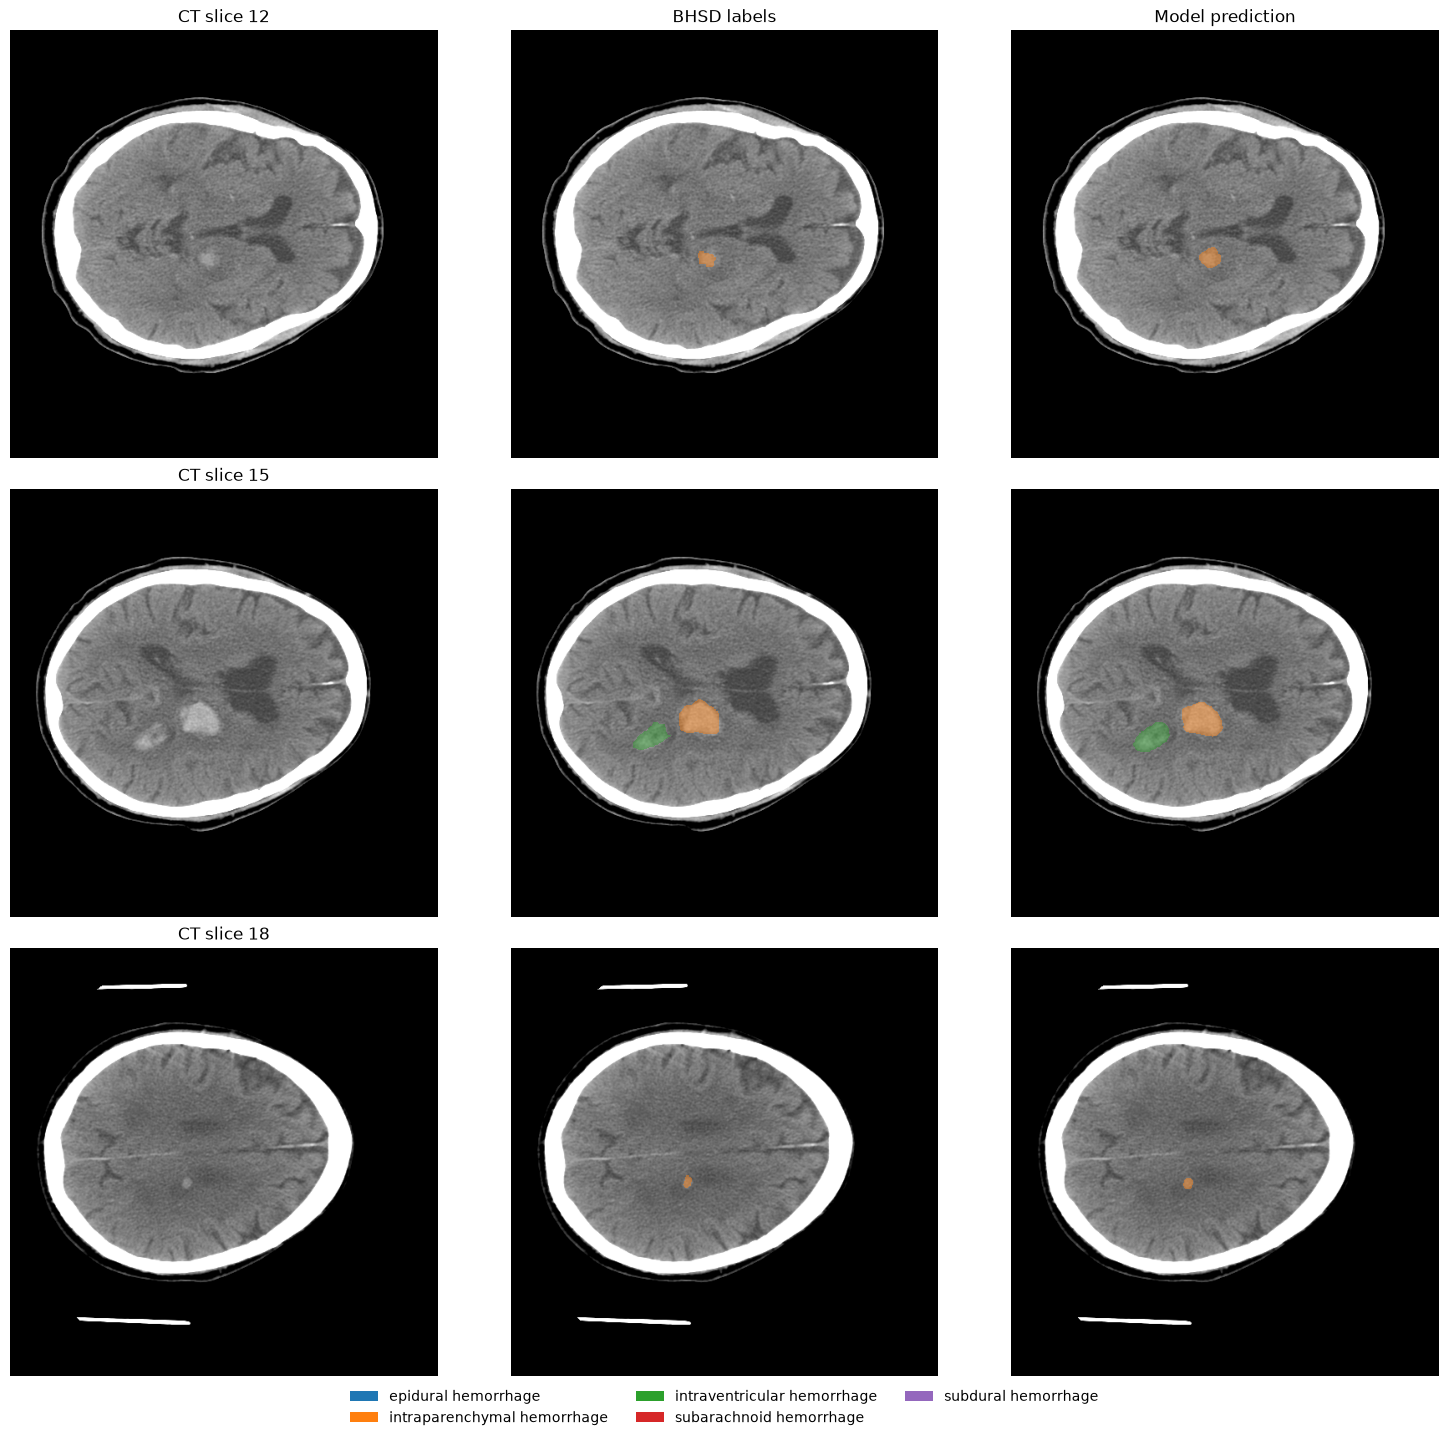

In [36]:
classes = pd.read_csv(evaluation_dir / "classes.csv").sort_values("class_id")
image_volume = np.moveaxis(
    np.asanyarray(nib.load(evaluation_dir / sample["image"]).dataobj), 2, 0
)
sample_case = (
    pd.read_csv(evaluation_dir / "cases.csv")
    .set_index("_row_id")
    .loc[sample["_row_id"]]
)
truth_volume = np.asanyarray(nib.load(evaluation_dir / sample_case["mask"]).dataobj)
candidate_slices = np.flatnonzero(truth_volume.any(axis=(1, 2)))
if candidate_slices.size == 0:
    candidate_slices = np.arange(len(truth_volume))
slice_indices = candidate_slices[
    np.linspace(0, len(candidate_slices) - 1, min(3, len(candidate_slices)), dtype=int)
]

palette = plt.get_cmap("tab10")
class_colors = {
    class_id: palette(index) for index, class_id in enumerate(classes["class_id"])
}
figure, axes = plt.subplots(
    len(slice_indices),
    3,
    figsize=(15, 4.5 * len(slice_indices) + 0.8),
    squeeze=False,
    layout="constrained",
)
for row_axes, slice_index in zip(axes, slice_indices):
    for axis in row_axes:
        axis.imshow(image_volume[slice_index], cmap="gray", vmin=0, vmax=255)
        axis.axis("off")
    row_axes[0].set_title(f"CT slice {slice_index}")
    for axis, labels in (
        (row_axes[1], truth_volume[slice_index]),
        (row_axes[2], predicted_labels[slice_index]),
    ):
        overlay = np.zeros((*labels.shape, 4))
        for class_id, color in class_colors.items():
            overlay[labels == class_id] = (*color[:3], 0.45)
        axis.imshow(overlay, interpolation="nearest")
axes[0, 1].set_title("BHSD labels")
axes[0, 2].set_title("Model prediction")
legend_handles = [
    Patch(facecolor=class_colors[row.class_id], label=row.class_name)
    for row in classes.itertuples()
]
figure.legend(
    handles=legend_handles, loc="outside lower center", ncols=3, frameon=False
)
plt.show()

### Optional cleanup

Run the next cell only when the selected endpoint is no longer needed, including by any other users or deployments.

- **Deleted:** the selected endpoint and all its deployments, including any reused here, stopping their inference compute charges.
- **Kept:** shared training compute, registered model, job outputs, and local data.

In [37]:
ml_client.online_endpoints.begin_delete(name=endpoint_name).result()

.................................................................